In [1]:

import os
import subprocess
from pathlib import Path

print("========== GPU CHECK ==========")

try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        timeout=20
    )
    print(result.stdout if result.returncode == 0 else result.stderr)
except Exception as e:
    print("GPU check error:", e)

print("\n========== FOLDER CHECK ==========")

print("Current directory:", os.getcwd())
print("\nContent of /content:")

for item in Path("/content").iterdir():
    print(item.name, "(Folder)" if item.is_dir() else "(File)")

print("\n========== CHECK COMPLETE ==========")


========== GPU CHECK ==========
Sat Oct 24 10:47:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------

In [2]:

import zipfile
import os

zip_path = "/content/concrete_crack_dataset.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        print("ZIP is valid:", z.testzip() is None)
        print("Total files:", len(z.namelist()))
else:
    print("Please check the uploaded ZIP filename.")


ZIP exists: False
Please check the uploaded ZIP filename.


In [3]:

import os

print(os.listdir("/content"))


['.config', '.ipynb_checkpoints', 'concrete_crack_project.zip', 'sample_data']


In [4]:

import os

files = os.listdir("/content")

for file in files:
    print(file)


.config
.ipynb_checkpoints
concrete_crack_project.zip
sample_data


In [5]:

import zipfile
import os

zip_path = "/content/concrete_crack_project.zip"
extract_path = "/content/crack_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction successful!")

for root, dirs, files in os.walk(extract_path):
    print(root, "Folders:", dirs, "Images:", len(files))
    if root.count(os.sep) >= 3:
        dirs.clear()


Extraction successful!
/content/crack_dataset Folders: ['sample_data', '.config'] Images: 2
/content/crack_dataset/sample_data Folders: [] Images: 6
/content/crack_dataset/.config Folders: ['configurations', 'logs'] Images: 8


In [6]:

import zipfile
import os
from pathlib import Path

zip_path = "/content/concrete_crack_project.zip"
extract_path = "/content/crack_dataset"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted successfully!")
print("Dataset location:", extract_path)
print("Extraction completed.")


Dataset extracted successfully!
Dataset location: /content/crack_dataset
Extraction completed.


In [8]:

import zipfile

zip_path = "/content/concrete_crack_project.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()
    print("Total files:", len(files))
    print("\nFirst 30 files:")
    for f in files[:30]:
        print(f)


Total files: 28

First 30 files:
.config/
sample_data/
README.md
concrete_crack_project.zip
.config/configurations/
.config/logs/
.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
.config/gce
.config/config_sentinel
.config/default_configs.db
.config/.last_update_check.json
.config/.last_survey_prompt.yaml
.config/.last_opt_in_prompt.yaml
.config/active_config
.config/configurations/config_default
.config/logs/2026.09.16/
.config/logs/2026.09.16/13.26.29.139725.log
.config/logs/2026.09.16/13.26.15.129583.log
.config/logs/2026.09.16/13.26.17.091876.log
.config/logs/2026.09.16/13.26.04.283691.log
.config/logs/2026.09.16/13.26.30.459687.log
.config/logs/2026.09.16/13.25.37.877256.log
sample_data/README.md
sample_data/anscombe.json
sample_data/california_housing_test.csv
sample_data/california_housing_train.csv
sample_data/mnist_train_small.csv
sample_data/mnist_test.csv


In [9]:

import os

for f in os.listdir("/content"):
    print(f)


.config
crack_dataset
.ipynb_checkpoints
concrete_crack_project.zip
archive.zip
sample_data


In [11]:

import os
import zipfile
from pathlib import Path

zip_files = list(Path("/content").glob("*.zip"))

dataset_zip = None

for file in zip_files:
    try:
        with zipfile.ZipFile(file, "r") as z:
            if z.testzip() is not None:
                continue

            names = [n.lower() for n in z.namelist()]

            has_positive = any("positive/" in n or "positive\\" in n for n in names)
            has_negative = any("negative/" in n or "negative\\" in n for n in names)

            print("Checked:", file.name)
            print("Positive folder:", has_positive)
            print("Negative folder:", has_negative)

            if has_positive and has_negative:
                dataset_zip = file
                break

    except (zipfile.BadZipFile, OSError):
        print("Invalid ZIP skipped:", file.name)

if dataset_zip is None:
    raise FileNotFoundError(
        "No valid ZIP containing Positive and Negative folders found."
    )

extract_path = Path("/content/crack_dataset")
extract_path.mkdir(exist_ok=True)

with zipfile.ZipFile(dataset_zip, "r") as z:
    z.extractall(extract_path)

print("\nSUCCESS!")
print("Selected:", dataset_zip.name)
print("Extracted to:", extract_path)


Checked: concrete_crack_project.zip
Positive folder: False
Negative folder: False
Invalid ZIP skipped: archive.zip
Checked: archive (2).zip
Positive folder: True
Negative folder: True

SUCCESS!
Selected: archive (2).zip
Extracted to: /content/crack_dataset


In [12]:

import os
import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split

base = Path("/content/crack_dataset")

# Locate Positive and Negative folders
folders = list(base.rglob("*"))

positive_dirs = [p for p in folders if p.is_dir() and p.name.lower() == "positive"]
negative_dirs = [p for p in folders if p.is_dir() and p.name.lower() == "negative"]

pairs = [(p, n) for p in positive_dirs for n in negative_dirs
         if p.parent == n.parent]

if not pairs:
    raise FileNotFoundError("Positive/Negative folders not found.")

pos_dir, neg_dir = pairs[0]

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

positive = [p for p in pos_dir.rglob("*") if p.suffix.lower() in extensions]
negative = [p for p in neg_dir.rglob("*") if p.suffix.lower() in extensions]

paths = positive + negative
labels = [1] * len(positive) + [0] * len(negative)

# 70% training and 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    paths, labels, test_size=0.30,
    random_state=42, stratify=labels
)

# 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)

output = Path("/content/crack_split")

if output.exists():
    shutil.rmtree(output)

for split, files, targets in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test)
]:
    for i, (file, label) in enumerate(zip(files, targets)):
        cls = "Positive" if label == 1 else "Negative"
        dest = output / split / cls
        dest.mkdir(parents=True, exist_ok=True)
        shutil.copy2(file, dest / f"{i}_{file.name}")

print("DATASET SPLIT COMPLETE")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))
print("Total:", len(paths))


DATASET SPLIT COMPLETE
Training: 28000
Validation: 6000
Testing: 6000
Total: 40000


In [13]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/crack_split/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/crack_split/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/crack_split/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("Training, validation and test datasets loaded!")


TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Found 28000 files belonging to 2 classes.
Found 6000 files belonging to 2 classes.
Found 6000 files belonging to 2 classes.
Training, validation and test datasets loaded!


In [14]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3
)

Epoch 1/3
875/875 ━━━━━━━━━━━━━━━━━━━━ 28s 24ms/step - accuracy: 0.9558 - loss: 0.1141 - val_accuracy: 0.9787 - val_loss: 0.0586
Epoch 2/3
875/875 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9824 - loss: 0.0563 - val_accuracy: 0.9893 - val_loss: 0.0322
Epoch 3/3
875/875 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9860 - loss: 0.0423 - val_accuracy: 0.9932 - val_loss: 0.0278


In [16]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9912 - loss: 0.0298
Test Loss: 0.029817646369338036
Test Accuracy: 99.12 %


In [17]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.concatenate([y.numpy().ravel() for x, y in test_ds])
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=test_ds.class_names
))

188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step
Confusion Matrix:
[[2978   22]
 [  31 2969]]

Classification Report:
              precision    recall  f1-score   support

    Negative       0.99      0.99      0.99      3000
    Positive       0.99      0.99      0.99      3000

    accuracy                           0.99      6000
   macro avg       0.99      0.99      0.99      6000
weighted avg       0.99      0.99      0.99      6000



In [20]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [21]:
model.save('/content/drive/MyDrive/concrete_crack_detection.keras')
print("Model saved successfully!")

Model saved successfully!


/tmp/ipykernel_1186/2019735643.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  actual = int(labels[i].numpy())


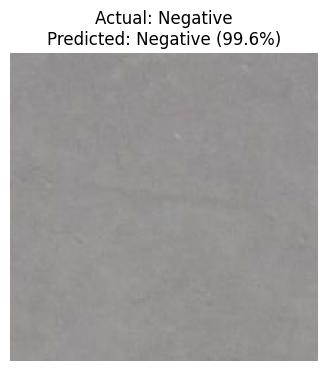

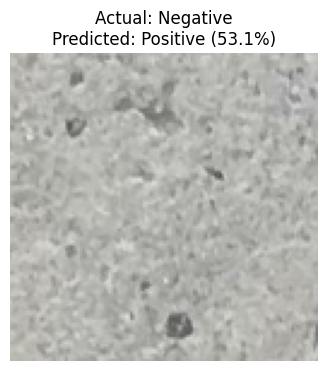

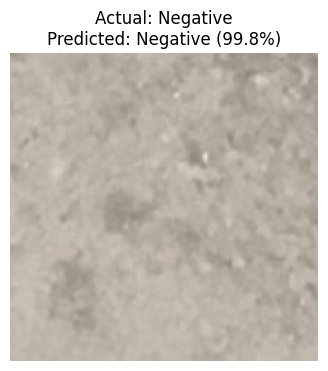

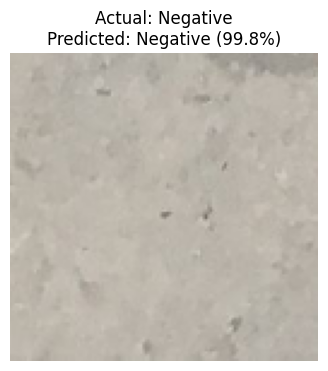

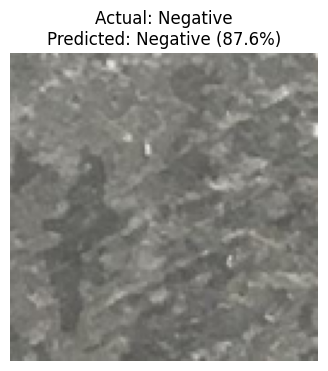

In [22]:
import matplotlib.pyplot as plt
import numpy as np

class_names = test_ds.class_names
shown = 0

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0).ravel()

    for i in range(len(images)):
        actual = int(labels[i].numpy())
        prob = float(predictions[i])
        predicted = int(prob >= 0.5)
        confidence = prob if predicted == 1 else 1 - prob

        plt.figure(figsize=(4, 4))
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(
            f"Actual: {class_names[actual]}\n"
            f"Predicted: {class_names[predicted]} "
            f"({confidence*100:.1f}%)"
        )
        plt.axis("off")
        plt.show()

        shown += 1
        if shown == 5:
            break

    if shown == 5:
        break